# Autocomplete & Autocorrect Data Analytics
**Oasis Infobyte SIP — Data Analytics L2 Task 5** · Steven Manuel Rios

Corpus: three public-domain **Project Gutenberg** novels: *Pride and Prejudice* (#1342), *The Adventures of Sherlock Holmes* (#1661) and *A Tale of Two Cities* (#98). Together they are about 2.2 MB and roughly 400k words.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

In [2]:
import re, nltk, time
from collections import Counter, defaultdict
for p, loc in [("stopwords", "corpora/stopwords"), ("punkt_tab", "tokenizers/punkt_tab")]:
    try: nltk.data.find(loc)
    except LookupError: nltk.download(p, quiet=True)
from nltk.corpus import stopwords
def strip_gutenberg(t):
    s = t.find("*** START OF"); e = t.find("*** END OF"); return t[t.find("\n", s) + 1:e] if s != -1 and e != -1 else t
raw = " ".join(strip_gutenberg(open(f"data/{f}", encoding="utf-8").read()) for f in ["pg1342.txt", "pg1661.txt", "pg98.txt"])
print(f"{len(raw):,} characters")

2,048,575 characters


## Preprocessing
The text is tokenised into sentences and then words, lowercased, and stripped of punctuation and digits. **Stopwords are kept for the n-gram model**, because next-word prediction needs words like *of the* (removing them would make suggestions ungrammatical). They are **removed for the frequency analysis** so the chart shows content words.

20,088 sentences | 372,207 tokens | vocab 14,931


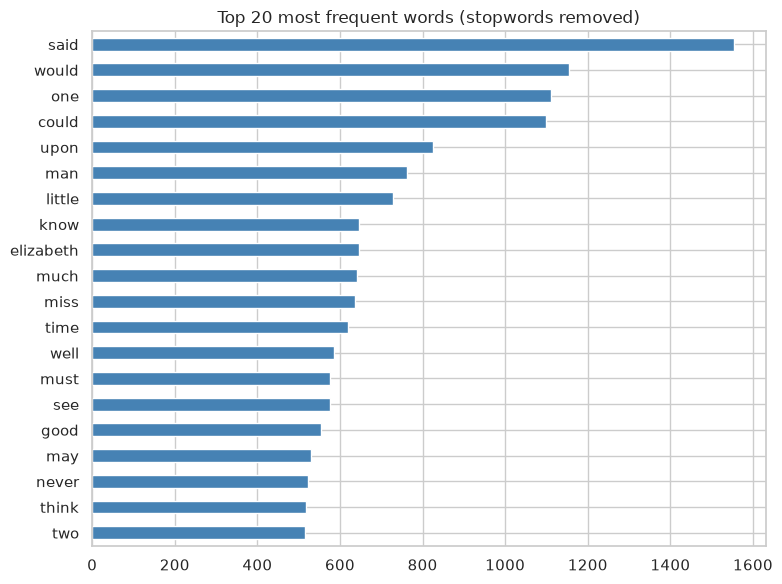

In [3]:
sents = [re.findall(r"[a-z]+(?:'[a-z]+)?", s.lower()) for s in nltk.sent_tokenize(raw)]
sents = [s for s in sents if len(s) > 1]
tokens = [w for s in sents for w in s]; stop = set(stopwords.words("english"))
content = [w for w in tokens if w not in stop and len(w) > 2]
print(f"{len(sents):,} sentences | {len(tokens):,} tokens | vocab {len(set(tokens)):,}")
top20 = Counter(content).most_common(20); pd.Series(dict(top20))[::-1].plot.barh(figsize=(8, 6), color="steelblue"); plt.title("Top 20 most frequent words (stopwords removed)"); save("top20_words")

## Autocomplete: n-gram models
Two approaches are compared:
* **Bigram**: P(next | previous word)
* **Trigram with backoff** ("stupid backoff"): use trigram counts if the two-word context was seen, otherwise fall back to bigram counts, then unigram counts

If the input ends in a partial word (no trailing space), the models complete that word instead, using unigram frequency filtered by the prefix and conditioned on the previous word when possible.

The model is trained on the first 90% of sentences, and the last 10% is held out for evaluation.

In [4]:
split = int(len(sents) * .9); train, test = sents[:split], sents[split:]
uni = Counter(); bi = defaultdict(Counter); tri = defaultdict(Counter)
for s in train:
    s = ["<s>"] + s
    for i, w in enumerate(s):
        if i: uni[w] += 1
        if i >= 1: bi[s[i - 1]][w] += 1
        if i >= 2: tri[(s[i - 2], s[i - 1])][w] += 1
def next_words(ctx, k=3, model="trigram"):
    ctx = ["<s>"] + ctx; out = []
    sources = ([tri.get(tuple(ctx[-2:]))] if model == "trigram" and len(ctx) >= 2 else []) + [bi.get(ctx[-1]), uni]
    for src in sources:
        for w, _ in (src or Counter()).most_common(k + 5):
            if w not in out: out.append(w)
            if len(out) == k: return out
    return out
def autocomplete(text, k=3, model="trigram"):
    words = re.findall(r"[a-z']+", text.lower())
    if text.endswith(" ") or not words: return next_words(words, k, model)
    part, ctx = words[-1], words[:-1]
    cand = Counter({w: c for w, c in (bi.get(ctx[-1], {}) if ctx else {}).items() if w.startswith(part)}) or Counter({w: c for w, c in uni.items() if w.startswith(part)})
    return [w for w, _ in cand.most_common(k)]
prefixes = ["i do not ", "it was the ", "my dear ", "sherlock ", "in the ", "she could not ", "mr ", "the best of ", "i have ", "what is the ", "elizab", "the gentle"]
pd.DataFrame({"prefix": prefixes, "bigram top-3": [autocomplete(p, model="bigram") for p in prefixes], "trigram top-3": [autocomplete(p) for p in prefixes]})

,prefix,bigram top-3,trigram top-3
0,i do not,"[be, to, a]","[know, think, make]"
1,it was the,"[other, same, door]","[only, first, name]"
2,my dear,"[friend, lizzy, sir]","[sir, lizzy, mr]"
3,sherlock,"[holmes, the, and]","[holmes, the, and]"
4,in the,"[other, same, door]","[world, morning, evening]"
5,she could not,"[be, to, a]","[be, have, help]"
6,mr,"[lorry, darcy, collins]","[darcy, collins, lorry]"
7,the best of,"[the, his, a]","[it, the, my]"
8,i have,"[been, a, no]","[been, no, not]"
9,what is the,"[other, same, door]","[first, only, case]"


### Autocomplete metrics
For every position in the held-out sentences, each model predicts the next word from the true preceding context.
* **Recall@3** (hit rate): the share of positions where the true next word is among the top 3 suggestions.
* **Precision@1**: the share of positions where the single top suggestion is correct (how often accepting the first suggestion is right).
* **Precision@3**: hits / suggestions shown, i.e. of all suggestions displayed, how many were the word the user wanted.

In [5]:
def eval_ac(model, maxn=20000):
    hits1 = hits3 = n = 0; t0 = time.time()
    for s in test:
        for i in range(len(s)):
            p = next_words(s[:i], 3, model); n += 1; hits3 += s[i] in p; hits1 += bool(p) and p[0] == s[i]
            if n >= maxn: break
        if n >= maxn: break
    return {"Precision@1": hits1 / n, "Recall@3": hits3 / n, "Precision@3": hits3 / (3 * n), "positions": n, "ms/prediction": (time.time() - t0) / n * 1000}
ac = pd.DataFrame({m: eval_ac(m) for m in ["bigram", "trigram"]}).T; ac.round(4)

,Precision@1,Recall@3,Precision@3,positions,ms/prediction
bigram,0.1268,0.2373,0.0791,20000.0,0.0744
trigram,0.1274,0.2400,0.0800,20000.0,0.0541


## Autocorrect
Three approaches are compared on **25 deliberately misspelled words** (typos covering insertion, deletion, substitution and transposition) plus **10 correctly spelled control words**. The controls measure false corrections.
1. **pyspellchecker**: Norvig-style candidates within edit distance ≤ 2, ranked by its built-in English word frequency.
2. **Custom Levenshtein + corpus frequency**: the candidate vocabulary is the corpus words. A candidate is ranked by the smallest Levenshtein distance, with ties broken by corpus frequency.
3. **Custom Damerau–Levenshtein** (counts a transposition as one edit) with the same corpus ranking.

In [6]:
from spellchecker import SpellChecker
import textdistance
cases = [("recieve", "receive"), ("teh", "the"), ("becuase", "because"), ("freind", "friend"), ("happend", "happened"), ("sherlok", "sherlock"), ("beleive", "believe"), ("acommodate", "accommodate"),
         ("gentelman", "gentleman"), ("sistr", "sister"), ("marriag", "marriage"), ("whcih", "which"), ("londn", "london"), ("famly", "family"), ("evry", "every"), ("adress", "address"), ("thier", "their"),
         ("knowlege", "knowledge"), ("wierd", "weird"), ("tommorow", "tomorrow"), ("seperate", "separate"), ("writting", "writing"), ("untill", "until"), ("plesure", "pleasure"), ("hapiness", "happiness")]
controls = ["house", "letter", "evening", "daughter", "window", "question", "certainly", "darcy", "watson", "prisoner"]
test_ac = [(w, c, True) for w, c in cases] + [(w, w, False) for w in controls]
vocab = Counter(tokens); words_by_len = defaultdict(list)
for w in vocab: words_by_len[len(w)].append(w)
def custom(word, dist):
    if word in vocab: return word
    best = None
    for L in range(len(word) - 2, len(word) + 3):
        for w in words_by_len.get(L, []):
            d = dist(word, w)
            if d <= 2 and (best is None or (d, -vocab[w]) < best[0]): best = ((d, -vocab[w]), w)
    return best[1] if best else word
spell = SpellChecker()
methods = {"pyspellchecker": lambda w: spell.correction(w) or w,
           "Levenshtein + corpus": lambda w: custom(w, textdistance.levenshtein.distance),
           "Damerau-Lev + corpus": lambda w: custom(w, textdistance.damerau_levenshtein.distance)}
out = pd.DataFrame([{"input": w, "expected": c, **{n: f(w) for n, f in methods.items()}} for w, c, _ in test_ac]); out

,input,expected,pyspellchecker,Levenshtein + corpus,Damerau-Lev + corpus
0,recieve,receive,receive,relieve,receive
1,teh,the,the,ten,the
2,becuase,because,because,because,because
3,freind,friend,friend,friend,friend
4,happend,happened,happened,happened,happened
5,sherlok,sherlock,sherlock,sherlock,sherlock
6,beleive,believe,believe,believe,believe
7,acommodate,accommodate,accommodate,accommodate,accommodate
8,gentelman,gentleman,gentleman,gentleman,gentleman
9,sistr,sister,sister,sister,sister


In [7]:
def ac_metrics(col):
    TP = FP = FN = TN = 0
    for (w, c, is_err), pred in zip(test_ac, out[col]):
        changed = pred != w
        if is_err: TP += changed and pred == c; FN += pred != c; FP += changed and pred != c
        else: FP += changed; TN += not changed
    return {"TP (fixed)": TP, "FN (missed/wrong)": FN, "FP (bad change)": FP, "TN (left alone)": TN, "accuracy on misspellings": TP / len(cases), "precision": TP / max(TP + FP, 1), "recall": TP / len(cases)}
acm = pd.DataFrame({m: ac_metrics(m) for m in methods}).T; acm

,TP (fixed),FN (missed/wrong),FP (bad change),TN (left alone),accuracy on misspellings,precision,recall
pyspellchecker,23.0,2.0,2.0,10.0,0.92,0.92,0.92
Levenshtein + corpus,20.0,5.0,5.0,10.0,0.80,0.80,0.80
Damerau-Lev + corpus,23.0,2.0,2.0,10.0,0.92,0.92,0.92


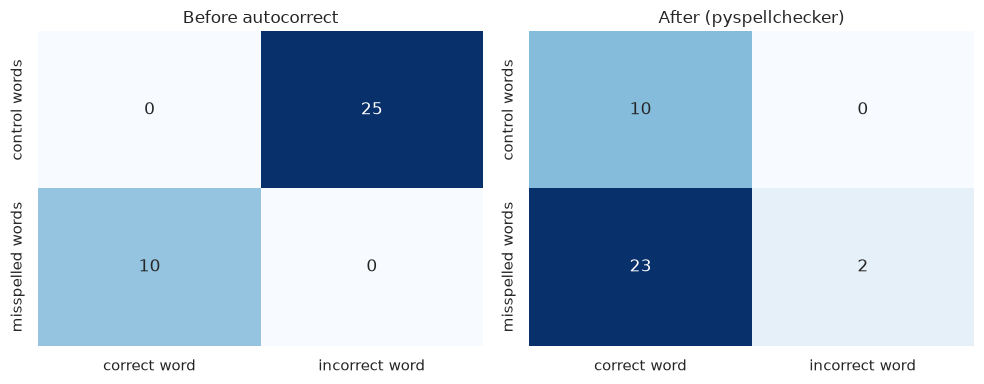

In [8]:
best = acm["accuracy on misspellings"].astype(float).idxmax()
before = np.array([[0, len(cases)], [len(controls), 0]])   # rows: truly misspelled? no/yes ; cols: correct / incorrect word
after_ok = (out[best] == out["expected"]).values
after = np.array([[after_ok[len(cases):].sum(), (~after_ok[len(cases):]).sum()], [after_ok[:len(cases)].sum(), (~after_ok[:len(cases)]).sum()]])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, m, t in zip(ax, [before, after], ["Before autocorrect", f"After ({best})"]):
    sns.heatmap(m, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=["correct word", "incorrect word"], yticklabels=["control words", "misspelled words"]); a.set_title(t)
save("autocorrect_confusion")

## Results
**Autocomplete** (20,000 held-out positions):
| Model | Precision@1 | Recall@3 | ms / prediction |
|---|---|---|---|
| Bigram | 0.127 | 0.237 | 0.07 |
| Trigram + backoff | **0.127** | **0.240** | 0.05 |

The trigram gives clearly better *qualitative* suggestions. After "i do not" it suggests *know, think, make* where the bigram gives *be, to, a*, and after "in the" it suggests *world, morning, evening* instead of a generic *other, same, door*. The aggregate gain is small, though, because about 400k training words leave most two-word contexts unseen, so the trigram backs off to bigrams most of the time.

**Autocorrect** (25 misspellings + 10 controls):
| Method | Fixed | Precision | Recall |
|---|---|---|---|
| pyspellchecker | 23/25 | 0.92 | 0.92 |
| Levenshtein + corpus | 20/25 | 0.80 | 0.80 |
| **Damerau–Levenshtein + corpus** | **23/25** | **0.92** | **0.92** |

All three methods left the 10 correct controls untouched (no false corrections). Plain Levenshtein fails on **transpositions** (*thier → thief*, *teh → ten*, *recieve → relieve*), because swapping two letters counts as 2 edits. Damerau–Levenshtein counts a swap as 1 edit and fixes these cases. Remaining errors: *evry → very* (equal distance, and *very* is more frequent) and *adress → dress* (*address* is rare in 19th-century novels).

## Limitations vs production systems (e.g. Gboard)
* **Corpus:** three 19th-century novels, not billions of modern, multilingual, user-specific sentences. Vocabulary such as *email* or *ok* is missing.
* **Model:** count-based n-grams with stupid backoff, no smoothing such as Kneser–Ney, and no neural language model. Gboard uses on-device neural LMs (LSTM/transformer) with **federated learning** and personalisation.
* **Context:** no keyboard geometry (spatial error models such as *q* next to *w*), no phonetic errors (*fone → phone*), no sentence-level context for real-word errors (*their/there*), and no user dictionary or contacts.
* **Evaluation:** a small hand-made typo list, while real systems measure keystroke savings and acceptance rates on live traffic.